<a href="https://colab.research.google.com/github/rakeshsaha2007/Real-Estate-Price-Predictor/blob/main/Real_Estate_Price_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Model Performance ---
Mean Squared Error (MSE): 0.01
R-squared Score (Accuracy): 1.00

--- New Prediction ---
For a house with 1800 Sq.Ft and 5 Rooms,
The estimated price is: 54.32 Lakhs!



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


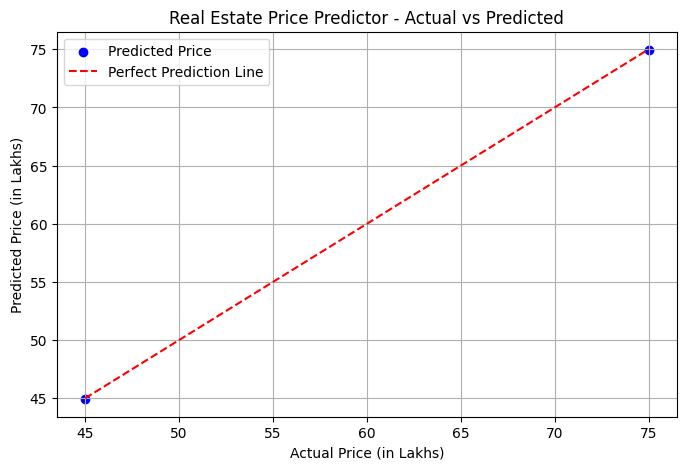

In [1]:
# Importing required libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Step 1: Creating a dummy dataset (10 houses: Square Footage, Room Count, and Price in Lakhs)
data = {
    'Square_Footage': [1000, 1500, 1200, 1800, 2000, 850, 900, 2200, 2500, 1300],
    'Room_Count': [2, 3, 2, 4, 4, 1, 2, 5, 5, 3],
    'Price_in_Lakhs': [30, 45, 36, 54, 60, 25, 27, 66, 75, 39]
}
df = pd.DataFrame(data)

# Step 2: Separating input features (X) and target variable (y)
X = df[['Square_Footage', 'Room_Count']]
y = df['Price_in_Lakhs']

# Step 3: Splitting the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Initializing and training the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 5: Predicting prices using the test data
y_pred = model.predict(X_test)

# Step 6: Evaluating the model's performance
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Model Performance ---")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared Score (Accuracy): {r2:.2f}\n")

# Step 7: Predicting the price of a new house (Dynamic Input for Lab Test)
# Change these values if the examiner asks for a different square footage or room count
new_sqft = 1800
new_rooms = 5

# Passing the new data to the model
new_house = [[new_sqft, new_rooms]]
new_price = model.predict(new_house)

print("--- New Prediction ---")
print(f"For a house with {new_sqft} Sq.Ft and {new_rooms} Rooms,")
print(f"The estimated price is: {new_price[0]:.2f} Lakhs!\n")

# Step 8: Plotting the Actual vs Predicted Prices
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='blue', label='Predicted Price')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', label='Perfect Prediction Line')

plt.xlabel('Actual Price (in Lakhs)')
plt.ylabel('Predicted Price (in Lakhs)')
plt.title('Real Estate Price Predictor - Actual vs Predicted')
plt.legend()
plt.grid(True)
plt.show()